In [13]:
from pathlib import Path
import subprocess
import sys
from google.colab import drive

DRIVE = Path('/content/drive')
drive.mount('/content/drive')

ROOT = DRIVE / "MyDrive" / "doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval"
assert ROOT.exists()
PACKAGE_DIR = ROOT / 'python_packages'
PACKAGE_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PACKAGE_DIR))
print(PACKAGE_DIR.resolve())

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.ticker import FuncFormatter, NullFormatter, FixedLocator
import cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm
import numpy as np
import string
import gc

sys.path.insert(0, str(ROOT / "src"))

DATA_ROOT = ROOT / "data"
PREDS_ROOT = ROOT/ "outputs" / "aa_geoph_fluids"

VAR_DS = "precip"

NFES = [10, 25, 50, 500]

FIGS_PATH = ROOT / "figures" / "nfe_analysis"
FIGS_PATH.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages


In [14]:
def open_nfe_sims(model, date="2014-04-30"):
    path = PREDS_ROOT / model / "extreme_days"
    list_datasets = []
    for nfe in NFES:
        fname = path / f"simulations_extreme_days_nfe{nfe}.nc"
        list_datasets.append(
            xr.open_dataset(
                fname,
            ).expand_dims(dim={"nfe": [nfe]})
        )
    return xr.concat(list_datasets, dim="nfe").sel(time=date)


models = ["DDPM", "FlowMatch"]

preds_models = {m: open_nfe_sims(m)[VAR_DS] for m in models }

da_y_test = xr.open_dataset(DATA_ROOT / "predictands" / f"pr_SESA_ERA5.nc").sel(
    time=preds_models[models[0]].time.values
)[VAR_DS]

In [15]:
mean_intensity_models = {m: da.mean(dim=("lat", "lon")) for m, da in preds_models.items()}

median_member_models = {
    m: abs(mean_int - mean_int.quantile(0.70, dim="member")).argmin(dim="member")
    for m, mean_int in mean_intensity_models.items()
}

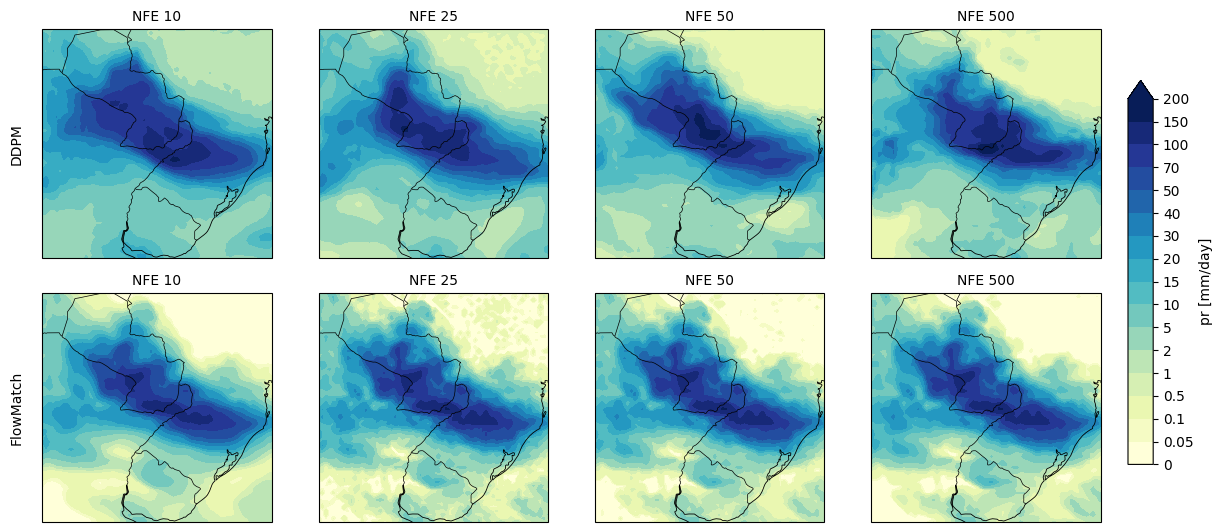

In [16]:
LEVELS = np.array([0.0, 0.05, 0.1, 0.5, 1, 2, 5, 10, 15, 20, 30, 40, 50, 70, 100, 150, 200])
CMAP = "YlGnBu"
cmap = plt.get_cmap(CMAP, len(LEVELS) - 1)
norm = BoundaryNorm(LEVELS, cmap.N)
proj = ccrs.PlateCarree()

models = list(preds_models)
nfes = preds_models[models[0]].nfe.values

fig, axes = plt.subplots(
    len(models), len(nfes),
    figsize=(3.5 * len(nfes), 3.2 * len(models)),
    subplot_kw={"projection": proj},
    squeeze=False
)

for i, model in enumerate(models):
    da = preds_models[model]
    mean_int = mean_intensity_models[model]
    median = mean_int.quantile(0.5, dim="member")

    idx = abs(mean_int - median).argmin(dim="member")

    for j, nfe in enumerate(nfes):
        ax = axes[i, j]
        member_idx = int(idx.sel(nfe=nfe).values)
        field = da.sel(nfe=nfe).isel(member=member_idx)

        im = ax.contourf(
            field.lon, field.lat, field,
            levels=LEVELS, cmap=cmap, norm=norm,
            extend="max", transform=proj
        )

        ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="black")
        ax.coastlines(linewidth=0.6)
        ax.set_title(f"NFE {nfe}", fontsize=10)

        if j == 0:
            ax.text(-0.08, 0.5, model, transform=ax.transAxes,
                    rotation=90, va="center", ha="right", fontsize=10)


cbar_ax = fig.add_axes([0.91, 0.20, 0.018, 0.60])
from matplotlib.ticker import FuncFormatter

cbar = fig.colorbar(im, cax=cbar_ax, ticks=LEVELS, extend="max")
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
cbar.set_label("pr [mm/day]")

plt.subplots_adjust(wspace=0.08, hspace=0.15)
plt.show()

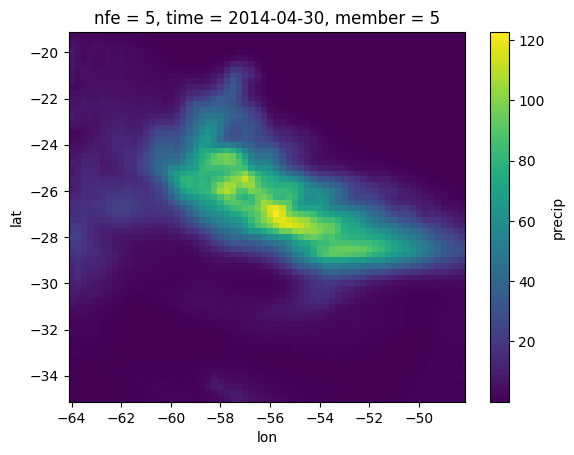

In [ ]:
preds_models['FlowMatch'].sel(nfe=5).sel(member=5).plot()

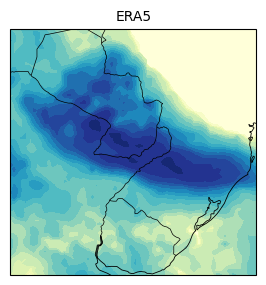

In [ ]:
models = list(preds_models)
nfes = preds_models[models[0]].nfe.values
i,j = 0,0
fig, axes = plt.subplots(
    1, 1,
    figsize=(3.5 * 1, 3.2 * 1),
    subplot_kw={"projection": proj},
    squeeze=False
)

ax = axes[i, j]
field = da_y_test
im = ax.contourf(
            field.lon, field.lat, field,
            levels=LEVELS, cmap=cmap, norm=norm,
            extend="max", transform=proj
)

ax.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor="black")
ax.coastlines(linewidth=0.6)
ax.set_title(f"ERA5", fontsize=10)



#cbar_ax = fig.add_axes([0.91, 0.20, 0.018, 0.60])
#cbar = fig.colorbar(im, cax=cbar_ax, ticks=LEVELS, extend="max")
#cbar.set_label("pr [mm/day]")

plt.subplots_adjust(wspace=0.08, hspace=0.15)
plt.show()